# Multivariate Gaussian

The multivariate Gaussian is a Gaussian distribution over multiple features (a random vector).

$$
\mathbf{X} \sim \mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})
$$

**Random vector** ($d$ features)

$$
\mathbf{X} = \begin{bmatrix} X_1 \\ X_2 \\ \vdots \\ X_d \end{bmatrix}
$$

**Mean vector**

$$
\boldsymbol{\mu} = \begin{bmatrix} \mu_1 \\ \mu_2 \\ \vdots \\ \mu_d \end{bmatrix}
$$

**Variance vector**

$$
\boldsymbol{\sigma}^2 = \begin{bmatrix} \sigma_1^2 \\ \sigma_2^2 \\ \vdots \\ \sigma_d^2 \end{bmatrix}
\\
\\
\\
$$

- Each $\sigma_i^2 = \mathrm{Var}(X_i)$ is the variance of feature $i$
- This vector is the diagonal of the covariance matrix $\boldsymbol{\Sigma}$ below

**Covariance matrix** ($d \times d$, symmetric, positive definite)

$$
\boldsymbol{\sigma} = \mathbb{E}\left[ (\mathbf{X}-\boldsymbol{\mu})(\mathbf{X}-\boldsymbol{\mu})^\top \right]

$$

<br>

$$
\boldsymbol{\Sigma} =
\begin{bmatrix}
\sigma_1^2 & \sigma_{12} & \cdots & \sigma_{1d} \\
\sigma_{21} & \sigma_2^2 & \cdots & \sigma_{2d} \\
\vdots & \vdots & \ddots & \vdots \\
\sigma_{d1} & \sigma_{d2} & \cdots & \sigma_d^2
\end{bmatrix}
$$

- Diagonal entries: variance of each feature, $\sigma_i^2 = \mathrm{Var}(X_i)$
- Off-diagonal entries: covariance between features, $\sigma_{ij} = \mathrm{Cov}(X_i, X_j)$
- If all features are independent, the off-diagonal entries are 0:
  $\boldsymbol{\Sigma} = \mathrm{diag}(\sigma_1^2, \sigma_2^2, \dots, \sigma_d^2)$

**Probability density function**

$$
f(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}\,|\boldsymbol{\Sigma}|^{1/2}}
\exp\!\left( -\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{x}-\boldsymbol{\mu}) \right)
$$

- $d$: number of features (dimension)
- $|\boldsymbol{\Sigma}|$: determinant of

In [40]:
import numpy as np
class MultiGaussian:
    def __init__(self, X):
        self.X = np.asarray(X, dtype=float)      # 리스트, 튜플 모두 OK
        self.N, self.D = self.X.shape
        self.mu = self.mean()
        self.sigma = self.cov()

    def mean(self):
        return np.mean(self.X, axis=0)

    def cov(self):
        dev = self.X - self.mu
        return dev.T @ dev / self.N

    def pdf(self, x):
        x = np.asarray(x, dtype=float)           # 리스트 -> 배열
        dev = x - self.mu
        inverse = np.linalg.inv(self.sigma)
        norm_const = np.sqrt((2 * np.pi) ** self.D * np.linalg.det(self.sigma))
        return np.exp(-0.5 * dev @ inverse @ dev) / norm_const

In [41]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()

print(iris.feature_names)
print(iris.target_names)
print(iris.data.shape)
print(iris.target.shape)
print(np.bincount(iris.target))


['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
(150, 4)
(150,)
[50 50 50]


let X1 sepal lenth, x2 is sepal width

[setosa]
  mu   : [5.006 3.428]
  sigma:
 [[0.122 0.097]
 [0.097 0.141]] 

[versicolor]
  mu   : [5.936 2.77 ]
  sigma:
 [[0.261 0.083]
 [0.083 0.097]] 

[virginica]
  mu   : [6.588 2.974]
  sigma:
 [[0.396 0.092]
 [0.092 0.102]] 



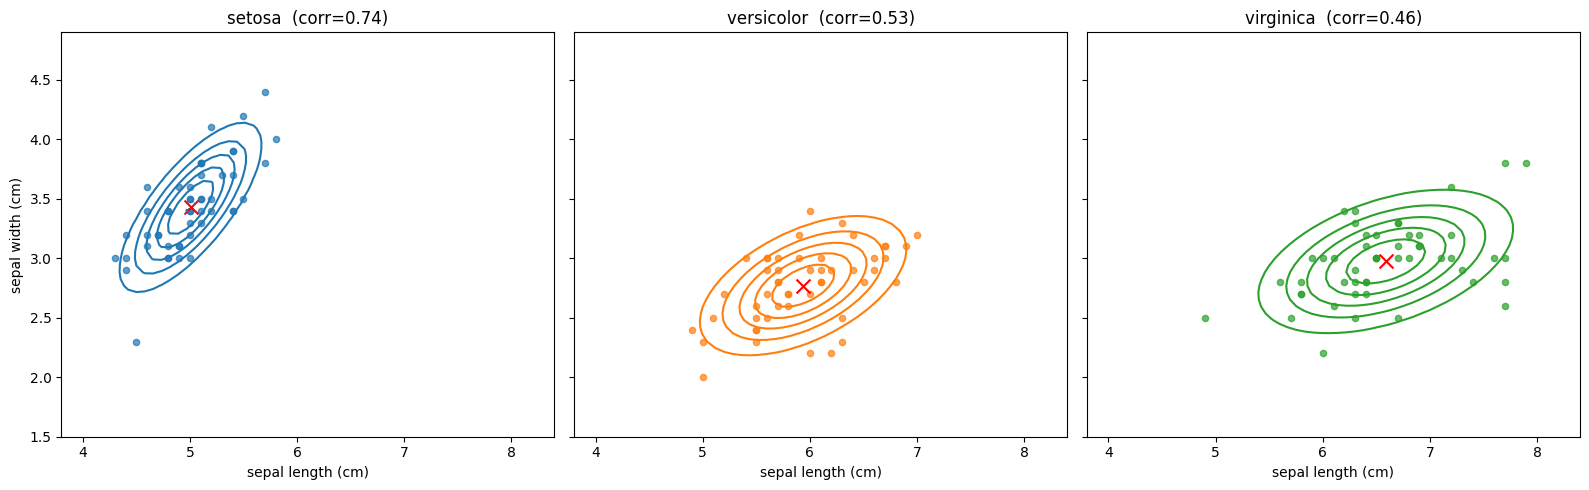

In [42]:
y= iris.target
colors = ["tab:blue", "tab:orange", "tab:green"]

#2feaures
data2 = iris.data[:,:2]

xlim = (data2[:, 0].min() - 0.5, data2[:, 0].max() + 0.5)
ylim = (data2[:, 1].min() - 0.5, data2[:, 1].max() + 0.5)

xs = np.linspace(*xlim, 60)
ys = np.linspace(*ylim, 60)
xx, yy = np.meshgrid(xs, ys)
pts = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

#number and object for drawing
for k, ax in enumerate(axes):
    X = iris.data[y==k][:,:2]
    g = MultiGaussian(X)

    #g is gaussian object fitiing X getting mu , corr given x
    zz = np.array([g.pdf(p) for p in pts]).reshape(xx.shape)
    
    corr = g.sigma[0, 1] / np.sqrt(g.sigma[0, 0] * g.sigma[1, 1])

    #plotiing

    ax.scatter(X[:, 0], X[:, 1], s=20, alpha=0.7, color=colors[k])
    
    #One 밀도가 같은 점들을 이은 타원

    ax.contour(xx, yy, zz, levels=6, colors=colors[k])
    
    ax.scatter(*g.mu, c="red", marker="x", s=100)
    ax.set_title(f"{iris.target_names[k]}  (corr={corr:.2f})")
    ax.set_xlabel(iris.feature_names[0])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    print(f"[{iris.target_names[k]}]")
    print("  mu   :", np.round(g.mu, 3))
    print("  sigma:\n", np.round(g.sigma, 3), "\n")

axes[0].set_ylabel(iris.feature_names[1])
plt.tight_layout()
plt.show()

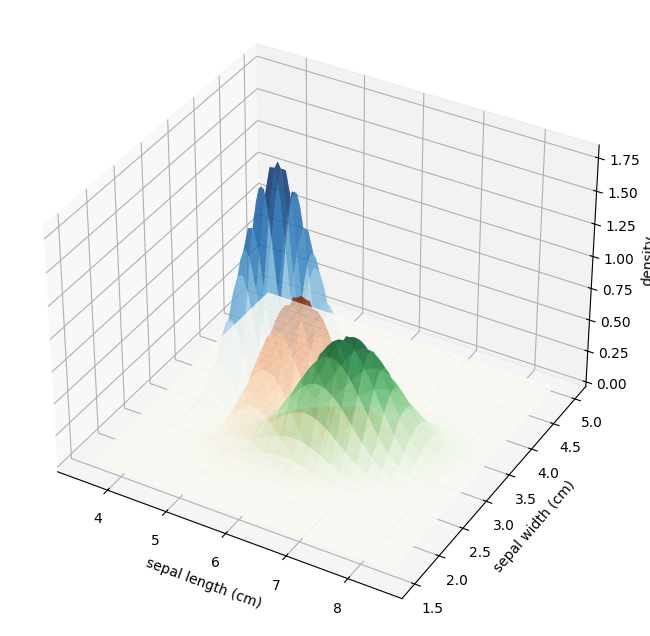

In [43]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
colors = ["Blues", "Oranges", "Greens"]

xs = np.linspace(3.5, 8.5, 60)
ys = np.linspace(1.5, 5.0, 60)
xx, yy = np.meshgrid(xs, ys)
pts = np.c_[xx.ravel(), yy.ravel()]

for k in range(3):
    Xk = iris.data[y == k][:, :2]
    gk = MultiGaussian(Xk)
    zz = np.array([gk.pdf(p) for p in pts]).reshape(xx.shape)
    ax.plot_surface(xx, yy, zz, cmap=colors[k], alpha=0.6, linewidth=0)

ax.set_xlabel(iris.feature_names[0])
ax.set_ylabel(iris.feature_names[1])
ax.set_zlabel("density")
ax.view_init(elev=35, azim=-60)
plt.show()

feature with 'sepal width (cm)', 'petal length (cm)

[setosa]
  mu   : [3.428 1.462]
  sigma:
 [[0.141 0.011]
 [0.011 0.03 ]] 

[versicolor]
  mu   : [2.77 4.26]
  sigma:
 [[0.097 0.081]
 [0.081 0.216]] 

[virginica]
  mu   : [2.974 5.552]
  sigma:
 [[0.102 0.07 ]
 [0.07  0.298]] 



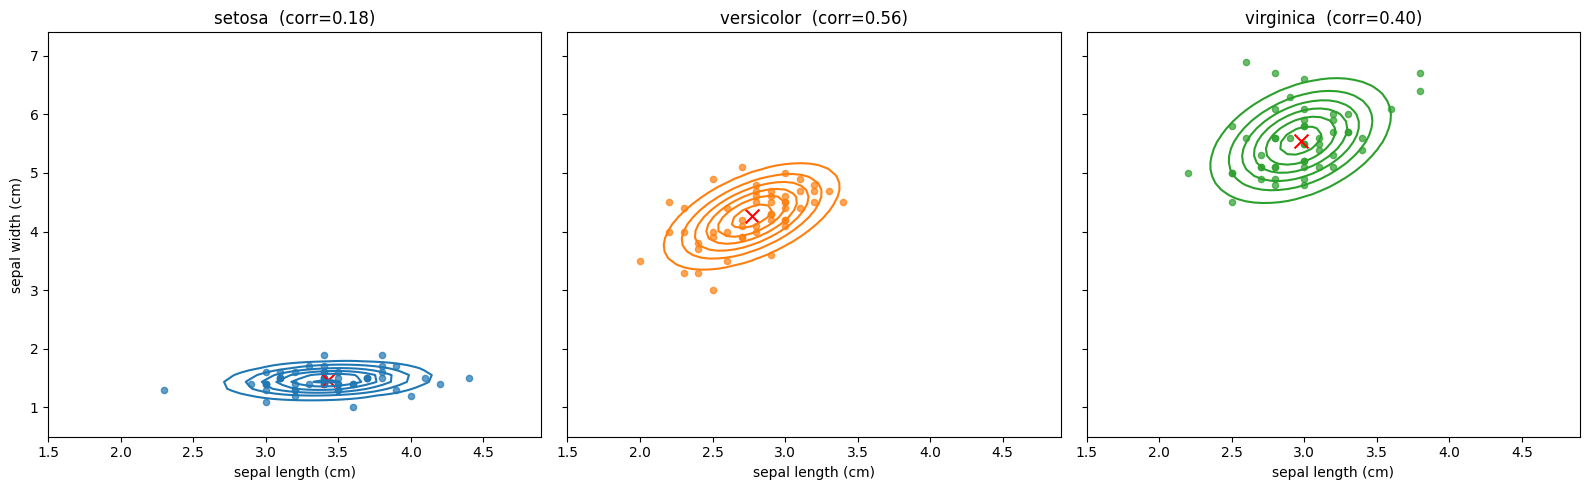

In [44]:
y= iris.target
colors = ["tab:blue", "tab:orange", "tab:green"]

#2feaures
data3 = iris.data[:,1:3]

xlim = (data3[:, 0].min() - 0.5, data3[:, 0].max() + 0.5)
ylim = (data3[:, 1].min() - 0.5, data3[:, 1].max() + 0.5)

xs = np.linspace(*xlim, 60)
ys = np.linspace(*ylim, 60)
xx, yy = np.meshgrid(xs, ys)
pts = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

#number and object for drawing
for k, ax in enumerate(axes):
    X = iris.data[y==k][:,1:3]
    g = MultiGaussian(X)

    #g is gaussian object fitiing X getting mu , corr given x
    zz = np.array([g.pdf(p) for p in pts]).reshape(xx.shape)
    
    corr = g.sigma[0, 1] / np.sqrt(g.sigma[0, 0] * g.sigma[1, 1])

    #plotiing

    ax.scatter(X[:, 0], X[:, 1], s=20, alpha=0.7, color=colors[k])
    
    #One 밀도가 같은 점들을 이은 타원

    ax.contour(xx, yy, zz, levels=6, colors=colors[k])
    
    ax.scatter(*g.mu, c="red", marker="x", s=100)
    ax.set_title(f"{iris.target_names[k]}  (corr={corr:.2f})")
    ax.set_xlabel(iris.feature_names[0])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    print(f"[{iris.target_names[k]}]")
    print("  mu   :", np.round(g.mu, 3))
    print("  sigma:\n", np.round(g.sigma, 3), "\n")

axes[0].set_ylabel(iris.feature_names[1])
plt.tight_layout()
plt.show()

[setosa]
  mu   : [5.006 1.462]
  sigma:
 [[0.122 0.016]
 [0.016 0.03 ]] 

[versicolor]
  mu   : [5.936 4.26 ]
  sigma:
 [[0.261 0.179]
 [0.179 0.216]] 

[virginica]
  mu   : [6.588 5.552]
  sigma:
 [[0.396 0.297]
 [0.297 0.298]] 



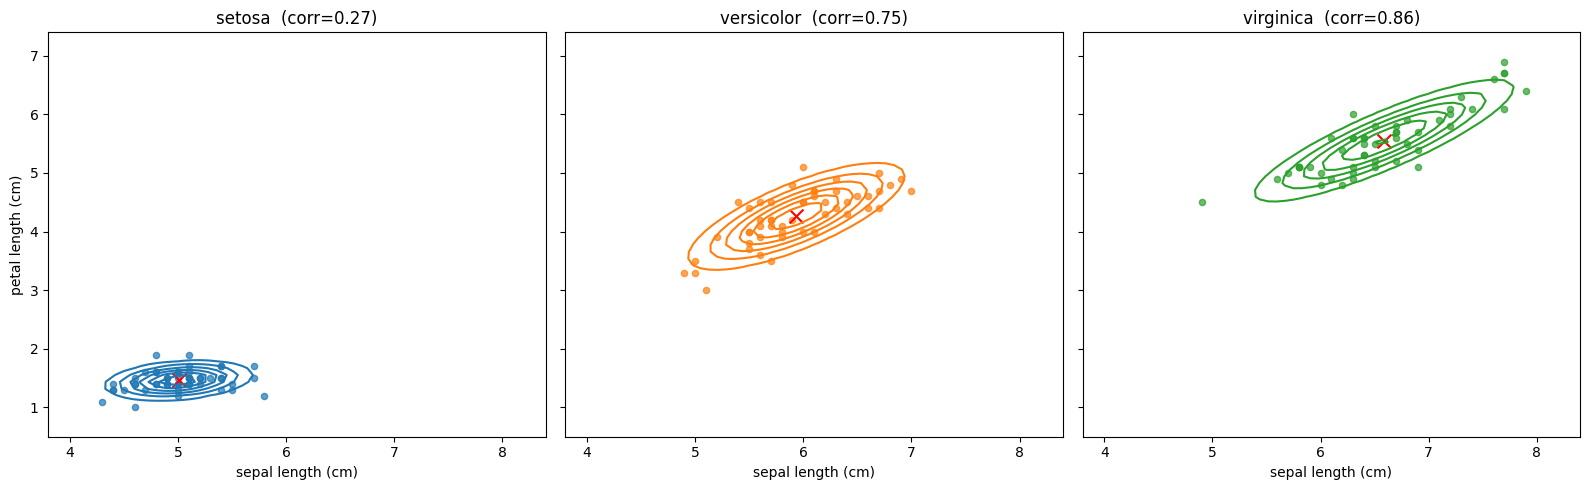

In [45]:
y= iris.target
colors = ["tab:blue", "tab:orange", "tab:green"]

#2feaures
cols = [0,2]
data3 = iris.data[:, cols]               # (150, 2)

xlim = (data3[:, 0].min() - 0.5, data3[:, 0].max() + 0.5)
ylim = (data3[:, 1].min() - 0.5, data3[:, 1].max() + 0.5)

xs = np.linspace(*xlim, 60)
ys = np.linspace(*ylim, 60)
xx, yy = np.meshgrid(xs, ys)
pts = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

#number and object for drawing
for k, ax in enumerate(axes):
    X = iris.data[y == k][:, cols]       # (50, 2)
    g = MultiGaussian(X)

    #g is gaussian object fitiing X getting mu , corr given x
    zz = np.array([g.pdf(p) for p in pts]).reshape(xx.shape)
    
    corr = g.sigma[0, 1] / np.sqrt(g.sigma[0, 0] * g.sigma[1, 1])

    #plotiing

    ax.scatter(X[:, 0], X[:, 1], s=20, alpha=0.7, color=colors[k])
    
    #One 밀도가 같은 점들을 이은 타원

    ax.contour(xx, yy, zz, levels=6, colors=colors[k])
    
    ax.scatter(*g.mu, c="red", marker="x", s=100)
    ax.set_title(f"{iris.target_names[k]}  (corr={corr:.2f})")
    ax.set_xlabel(iris.feature_names[cols[0]])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    print(f"[{iris.target_names[k]}]")
    print("  mu   :", np.round(g.mu, 3))
    print("  sigma:\n", np.round(g.sigma, 3), "\n")

axes[0].set_ylabel(iris.feature_names[cols[1]])
plt.tight_layout()
plt.show()

train: (105, 2)  test: (45, 2)
[setosa] mu=[1.434 0.249]
[versicolor] mu=[4.229 1.314]
[virginica] mu=[5.609 2.04 ]
train acc: 0.971
test  acc: 1.000
틀린 개수: 0 / 45


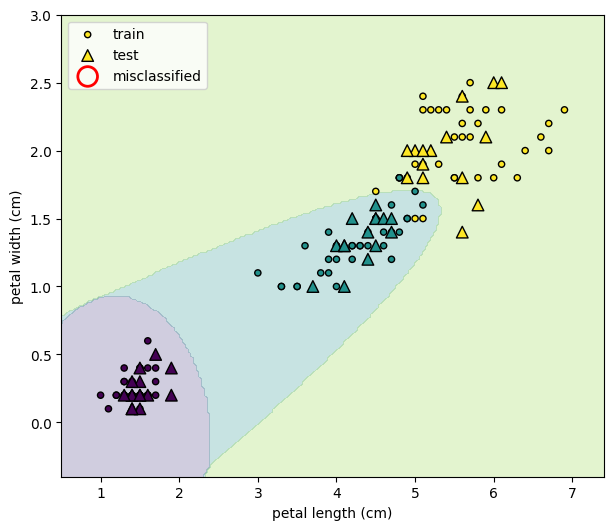

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
cols = [2,3]
X,y = iris.data[:,cols] , iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

print("train:", X_train.shape, " test:", X_test.shape)   # (105, 2), (45, 2)

##gs model이 총 3개
gs = [MultiGaussian(X_train[y_train == k]) for k in range(3)]

for k, g in enumerate(gs):
    print(f"[{iris.target_names[k]}] mu={np.round(g.mu, 3)}")

def predict(gs,X):
    #arg max는 인덱스를 저장한다
    #gs 마다 pdf의 밀도값 넣고 가장 높은 확률에 대한 index를 반환
    
    return np.array([np.argmax([g.pdf(x) for g in gs]) for x in X])

train_acc = np.mean(predict(gs, X_train) == y_train)
test_acc  = np.mean(predict(gs, X_test) == y_test)
print(f"train acc: {train_acc:.3f}")
print(f"test  acc: {test_acc:.3f}")

# 4) 틀린 테스트 샘플 확인
preds = predict(gs, X_test)
wrong = preds != y_test
print("틀린 개수:", wrong.sum(), "/", len(y_test))

# 5) 시각화: 결정 경계 + train/test 점
pad = 0.5
xs = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 200)
ys = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 200)
xx, yy = np.meshgrid(xs, ys)
grid = np.c_[xx.ravel(), yy.ravel()]
zz = predict(gs, grid).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5, 2.5], cmap="viridis")
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=20, edgecolor="k", label="train")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=70, marker="^", edgecolor="k", label="test")
plt.scatter(X_test[wrong, 0], X_test[wrong, 1], s=200, facecolors="none",
            edgecolors="red", linewidths=2, label="misclassified")
plt.xlabel(iris.feature_names[cols[0]])
plt.ylabel(iris.feature_names[cols[1]])
plt.legend()
plt.show()
